In [1]:
# Import Libraries & Load Cleaned Dataset
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visualization styling
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

# Load the processed dataset
data_path = '../cleaned_customer_data.csv' if os.path.exists('../cleaned_customer_data.csv') else 'cleaned_customer_data.csv'
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded. Dimensions: {df.shape}")
display(df.head(3))

Dataset successfully loaded. Dimensions: (2237, 34)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Customer_Age,Total_Children,Is_Parent,Total_Spending,Total_Purchases,Total_Accepted_Cmp,Enrollment_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,69,0,0,1617,22,0,5133
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,72,2,1,27,4,0,4583
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,61,0,0,776,20,0,4782


In [2]:
# Descriptive Statistics for Key Analytical Variables
key_metrics = ['Customer_Age', 'Income', 'Total_Spending', 'Total_Purchases', 'Total_Accepted_Cmp']
summary_table = df[key_metrics].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
summary_table.rename(columns={'50%': 'median'}, inplace=True)

print("Executive Summary Statistics of Key Metrics:")
display(summary_table)

Executive Summary Statistics of Key Metrics:


,count,mean,std,min,median,max
Customer_Age,2237.0,57.132767,11.790994,30.0,56.0,126.0
Income,2237.0,51939.645954,21411.279983,1730.0,51148.0,162397.0
Total_Spending,2237.0,605.744747,601.839257,5.0,396.0,2525.0
Total_Purchases,2237.0,12.543138,7.206732,0.0,12.0,32.0
Total_Accepted_Cmp,2237.0,0.297720,0.678615,0.0,0.0,4.0


In [3]:
# Non-Parametric Hypothesis Testing (Mann-Whitney U Test)
responders_spending = df[df['Response'] == 1]['Total_Spending']
non_responders_spending = df[df['Response'] == 0]['Total_Spending']

u_stat, p_value_spending = stats.mannwhitneyu(responders_spending, non_responders_spending, alternative='two-sided')

print("--- Hypothesis Test 1: Total Spending vs Campaign Response ---")
print(f"Responders Mean Spending: ${responders_spending.mean():.2f}")
print(f"Non-Responders Mean Spending: ${non_responders_spending.mean():.2f}")
print(f"Mann-Whitney U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value_spending:.5e}")

if p_value_spending < 0.05:
    print("Conclusion: Reject Null Hypothesis (H0). There is a statistically significant difference in spending between responders and non-responders.")
else:
    print("Conclusion: Fail to Reject Null Hypothesis (H0).")

--- Hypothesis Test 1: Total Spending vs Campaign Response ---
Responders Mean Spending: $987.39
Non-Responders Mean Spending: $538.76
Mann-Whitney U Statistic: 440734.00
P-value: 1.45205e-29
Conclusion: Reject Null Hypothesis (H0). There is a statistically significant difference in spending between responders and non-responders.


In [4]:
# Chi-Square Test of Independence (Education vs Response)
contingency_table = pd.crosstab(df['Education'], df['Response'])
chi2_stat, p_value_edu, dof, expected = stats.chi2_contingency(contingency_table)

print("--- Hypothesis Test 2: Education Level vs Campaign Response ---")
display(contingency_table)
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-value: {p_value_edu:.5f}")

if p_value_edu < 0.05:
    print("Conclusion: Reject Null Hypothesis (H0). Education level and campaign response are statistically dependent.")
else:
    print("Conclusion: Fail to Reject Null Hypothesis (H0).")

--- Hypothesis Test 2: Education Level vs Campaign Response ---


Response,0,1
Education,,
2n Cycle,180,22
Basic,52,2
Graduation,974,152
Master,313,57
PhD,384,101


Chi-Square Statistic: 23.1018
Degrees of Freedom: 4
P-value: 0.00012
Conclusion: Reject Null Hypothesis (H0). Education level and campaign response are statistically dependent.


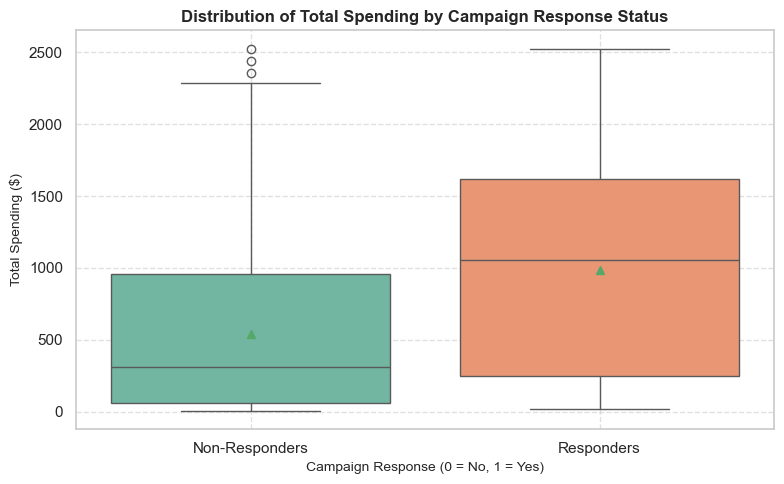

In [5]:
# Visualizing Total Spending Distribution by Campaign Response
plt.figure(figsize=(8, 5))
sns.boxplot(x='Response', y='Total_Spending', data=df, hue='Response', palette='Set2', legend=False, showmeans=True)
plt.title('Distribution of Total Spending by Campaign Response Status', fontsize=12, fontweight='bold')
plt.xlabel('Campaign Response (0 = No, 1 = Yes)', fontsize=10)
plt.ylabel('Total Spending ($)', fontsize=10)
plt.xticks([0, 1], ['Non-Responders', 'Responders'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save figure for portfolio documentation
plt.savefig('spending_vs_response_boxPlot.png', dpi=300)
plt.show()